In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

# import time
# import copy
import gc
import math

import matplotlib.pyplot as plt
import seaborn as sns
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from utils import get_opt, get_loaders, eval_ppl

In [2]:
DEV = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Load

## Model

In [3]:
# model_name = "HuggingFaceTB/SmolLM2-135M"
model_name = "HuggingFaceTB/SmolLM2-1.7B"

model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

## Datasets

In [4]:
# n_samples = 32
# n_samples = 128
n_samples = 1

dataloader, testloader = get_loaders(
    "c4", nsamples=n_samples, seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (8597 > 8192). Running this sequence through the model will result in indexing errors


In [5]:
# wiki_dataloader, wiki_testloader = get_loaders(
#     'wikitext2', seed=0, model=model_name, seqlen=model.seqlen
# )

# Genetic algorithm

In [41]:
# ------------------------------------------------------------
# GA utilities
# ------------------------------------------------------------

def create_random_individual(T, L, keep_ratio):
    """
    Creates binary matrix with exactly k ones.
    """
    total = T * L
    k = int(total * keep_ratio)

    flat = torch.zeros(total, dtype=torch.bfloat16)
    idx = torch.randperm(total)[:k]
    flat[idx] = 1.0
    
    return flat.view(T, L)


def mutate(individual, mutation_rate=0.02):
    T, L = individual.shape
    total = T * L
    k = individual.sum().int().item()

    flat = individual.view(-1)

    for i in range(total):
        if random.random() < mutation_rate:
            flat[i] = 1 - flat[i]

    # enforce exact number of ones again
    ones_idx = torch.where(flat == 1)[0]
    zeros_idx = torch.where(flat == 0)[0]

    if len(ones_idx) > k:
        drop = torch.randperm(len(ones_idx))[:len(ones_idx) - k]
        flat[ones_idx[drop]] = 0
    elif len(ones_idx) < k:
        add = torch.randperm(len(zeros_idx))[:k - len(ones_idx)]
        flat[zeros_idx[add]] = 1

    return flat.view(T, L)


def swap_mutation(individual, n_swaps=20):
    flat = individual.view(-1)
    ones = torch.where(flat == 1)[0]
    zeros = torch.where(flat == 0)[0]

    for _ in range(n_swaps):
        i = ones[torch.randint(len(ones), (1,))]
        j = zeros[torch.randint(len(zeros), (1,))]
        flat[i], flat[j] = 0, 1

    return flat.view_as(individual)


def uniform_crossover_sparse(parent1, parent2, keep_ratio):
    """
    parent1, parent2: [T, L] binary tensors (0/1)
    keep_ratio: fraction of ones to keep (e.g. 0.7)
    """

    T, L = parent1.shape
    total = T * L
    k = int(total * keep_ratio)

    # --- Step 1: Uniform crossover
    mask = torch.rand_like(parent1, dtype=torch.float32) < 0.5
    child = torch.where(mask, parent1, parent2)

    # --- Step 2: Enforce exact sparsity
    flat = child.view(-1)

    current_ones = flat.sum().int().item()

    if current_ones > k:
        # randomly turn off excess ones
        ones_idx = torch.where(flat == 1)[0]
        drop = torch.randperm(len(ones_idx))[: current_ones - k]
        flat[ones_idx[drop]] = 0

    elif current_ones < k:
        # randomly turn on missing ones
        zeros_idx = torch.where(flat == 0)[0]
        add = torch.randperm(len(zeros_idx))[: k - current_ones]
        flat[zeros_idx[add]] = 1

    return flat.view(T, L)

def crossover_layers(parent1, parent2, keep_ratio):
    """
    parent1, parent2: [T, L] binary tensors (0/1)
    keep_ratio: fraction of ones to keep globally (e.g. 0.7)

    Crossover is performed per column (whole columns selected).
    """

    T, L = parent1.shape
    total = T * L
    k = int(total * keep_ratio)

    # --- Step 1: Column-wise uniform crossover
    # For each column choose parent1 or parent2
    col_mask = torch.rand(L, device=parent1.device) < 0.5  # [L]

    # Expand mask over rows
    child = torch.where(
        col_mask.unsqueeze(0).expand(T, L),
        parent1,
        parent2
    )

    # --- Step 2: Enforce exact global sparsity
    flat = child.reshape(-1)
    current_ones = flat.sum().int().item()

    if current_ones > k:
        ones_idx = torch.where(flat == 1)[0]
        drop = torch.randperm(len(ones_idx), device=parent1.device)[: current_ones - k]
        flat[ones_idx[drop]] = 0

    elif current_ones < k:
        zeros_idx = torch.where(flat == 0)[0]
        add = torch.randperm(len(zeros_idx), device=parent1.device)[: k - current_ones]
        flat[zeros_idx[add]] = 1

    return flat.view(T, L)

def crossover_token_routes(parent1, parent2, keep_ratio):
    """
    parent1, parent2: [T, L] binary tensors (0/1)
    keep_ratio: fraction of ones to keep globally (e.g. 0.7)

    Crossover is performed per row (whole rows selected).
    """

    T, L = parent1.shape
    total = T * L
    k = int(total * keep_ratio)

    device = parent1.device

    # --- Step 1: Row-wise uniform crossover
    # For each row choose parent1 or parent2
    row_mask = torch.rand(T, device=device) < 0.5  # [T]

    child = torch.where(
        row_mask.unsqueeze(1).expand(T, L),
        parent1,
        parent2
    )

    # --- Step 2: Enforce exact global sparsity (element-level)
    flat = child.reshape(-1)
    current_ones = flat.sum().int().item()

    if current_ones > k:
        ones_idx = torch.where(flat == 1)[0]
        drop = torch.randperm(len(ones_idx), device=device)[: current_ones - k]
        flat[ones_idx[drop]] = 0

    elif current_ones < k:
        zeros_idx = torch.where(flat == 0)[0]
        add = torch.randperm(len(zeros_idx), device=device)[: k - current_ones]
        flat[zeros_idx[add]] = 1

    return flat.view(T, L)



def mate(parent1, parent2, keep_ratio, noise_std=0.1):
    """
    Combine parents:
    score = p1 + p2 + noise
    keep top k elements
    """
    T, L = parent1.shape
    total = T * L
    k = int(total * keep_ratio)

    score = parent1 + parent2
    score = score + torch.randn_like(score) * noise_std

    flat_score = score.view(-1)
    _, topk_idx = torch.topk(flat_score, k)

    child = torch.zeros(total, dtype=torch.bfloat16)
    child[topk_idx] = 1.0

    return child.view(T, L)

In [42]:
def create_block_pruner_individual(T, L, keep_ratio=0.7):
    num_skip_rows = round(L * (1-keep_ratio))
    row_indices = [12, 5, 13, 21, 10, 15, 9, 20, 19, 8, 2, 18, 17, 14, 16, 3, 23, 4, 1, 22, 11, 6, 0, 7]  # based on block_pruner skip order
    rows_with_zeros = row_indices[:num_skip_rows]

    mat = torch.ones(T, L, dtype=torch.bfloat16)
    mat[:, rows_with_zeros] = 0
    return mat

def create_rnd_layer_individual(T, L, keep_ratio=0.7):
    num_skip_rows = round(L * (1-keep_ratio))
    row_indices = torch.randperm(L)
    rows_with_zeros = row_indices[:num_skip_rows]

    mat = torch.ones(T, L, dtype=torch.bfloat16)
    mat[:, rows_with_zeros] = 0
    return mat

def generate_noisy_variants(base_mat, num_variants=5, noise_prob=0.05):
    """
    Generate multiple matrices similar to base_mat with small random flips.
    """
    variants = []
    T, L = base_mat.shape

    for _ in range(num_variants):
        # copy base
        mat = base_mat.clone()
        # create random mask for flipping
        flip_mask = torch.rand(T, L) < noise_prob
        mat[flip_mask] = 1 - mat[flip_mask]  # flip 0 <-> 1
        variants.append(mat)
    return variants


In [43]:
def tournament_select(population, fitnesses, k=3):
    """
    population: list of individuals
    fitnesses: list of fitness values (lower is better if using PPL)
    k: tournament size
    """
    selected_indices = random.sample(range(len(population)), k)
    best_idx = min(selected_indices, key=lambda i: fitnesses[i])  # minimize fitness
    return population[best_idx]


def reproduce_with_tournament(population, fitnesses, population_size, num_elite,
                               keep_ratio, n_swaps, tournament_k=3):
    
    new_population = population[:num_elite].copy()

    while len(new_population) < population_size:
        p1 = tournament_select(population, fitnesses, k=tournament_k)
        p2 = tournament_select(population, fitnesses, k=tournament_k)

        # child = crossover_token_routes(p1, p2, keep_ratio)
        child = crossover_layers(p1, p2, keep_ratio)
        child = swap_mutation(child, n_swaps)

        new_population.append(child)

    return new_population

In [9]:
def new_population(elites, population_size, keep_ratio, n_swaps):
    new_population = elites.copy()
    while len(new_population) < population_size:
        p1, p2 = random.sample(elites, 2)
        # child = mate(p1, p2, keep_ratio)
        # child = uniform_crossover_sparse(p1, p2, keep_ratio)
        child = crossover_token_routes(p1, p2, keep_ratio)
        # child = mutate(child, mutation_rate)
        child = swap_mutation(child, n_swaps)
        new_population.append(child)
    return new_population

In [39]:
# ------------------------------------------------------------
# Main GA loop
# ------------------------------------------------------------
@torch.no_grad()
def genetic_search(
    model,
    input_ids,
    population_size=30,
    chunk_size=8,
    generations=50,
    keep_ratio=0.7,     # 70% kept = 30% skipped
    elite_fraction=0.25,
    mutation_rate=0.02,
    init_noise=0.05
):
    stats = {'ppl': [], 'mask': []}

    T = input_ids.shape[1]
    L = model.config.num_hidden_layers
    n_swaps = int(T * L * mutation_rate)

    # ---- initialize population
    # bp_matrix = create_block_pruner_individual(T, L, keep_ratio)
    # population = [bp_matrix] + [
    # population = [
    #     create_rnd_layer_individual(T, L, keep_ratio)
    #     for _ in range((population_size)//2)
    # ] + [
    #     create_random_individual(T, L, keep_ratio)
    #     for _ in range(math.ceil((population_size)/2))
    # ]
    population = [
        create_rnd_layer_individual(T, L, keep_ratio)
        for _ in range(population_size)
    ]

    input_ids = input_ids.to(DEV)

    best_solution = None
    best_score = float("inf")
    elite_ppl = None
    num_elite = int(population_size * elite_fraction)

    for gen in range(generations):
        if gen == 0:
            # evaluate
            fitness = evaluate_population_chunked(model, input_ids, population, chunk_size=chunk_size)
        else:
            fitness = evaluate_population_chunked(model, input_ids, population[num_elite:], chunk_size=chunk_size)
            fitness = torch.cat([elite_ppl, fitness])
            
        # sort by fitness
        sorted_indices = sorted(range(len(fitness)), key=lambda i: fitness[i])
        population = [population[i] for i in sorted_indices]
        fitness = [fitness[i] for i in sorted_indices]

        print(f"Generation {gen} | Best PPL: {fitness[0]:.4f}\t{' '.join([str(x.item()) for x in fitness[:num_elite]])} | {' '.join([str(x.item()) for x in fitness[num_elite:2*num_elite]])}")
        stats['ppl'].append(fitness[0].item())
        if fitness[0] < best_score:
            best_score = fitness[0]
            best_solution = population[0].clone()
            stats['mask'].append(best_solution)

        # ---- selection
        elites = population[:num_elite]
        elite_ppl = torch.stack(fitness[:num_elite])

        # ---- reproduction
        population = reproduce_with_tournament(
            population,
            fitness,              # list of PPLs (same order as population)
            population_size,
            num_elite,
            keep_ratio,
            n_swaps,
            tournament_k=3
        )
        # population = new_population(elites, population_size, keep_ratio, n_swaps)

    return best_solution, best_score, stats, population

# Model modification

In [12]:
class MaskedMLP(nn.Module):
    def __init__(self, mlp):
        super().__init__()
        self.mlp = mlp
        self.mask = None

    def forward(self, h):
        if self.mask is not None:
            return self.mlp(h) * self.mask
        return self.mlp(h)

In [13]:
keep_ratio = 0.7
for layer in model.model.layers:
    layer.mlp = MaskedMLP(layer.mlp)

In [14]:
def set_mask(model, mask):
    for i, layer in enumerate(model.model.layers):
        layer.mlp.mask = mask[:, :, i].unsqueeze(-1)

In [15]:
# def get_loss(outputs, labels):
#     lm_logits = outputs.logits.cpu()
#     shift_logits = lm_logits[:, :-1, :].contiguous()
#     shift_labels = labels[:, 1:].cpu()
#     loss_fct = nn.CrossEntropyLoss(reduction="none")
#     return loss_fct(
#         shift_logits.reshape(-1, shift_logits.size(-1)),
#         shift_labels.reshape(-1)
#     )


In [16]:
def get_loss(outputs, labels):
    lm_logits = outputs.logits          # [P, T, V]
    
    shift_logits = lm_logits[:, :-1, :].contiguous()  # [P, T-1, V]
    shift_labels = labels[:, 1:].contiguous()         # [P, T-1]

    P, Tm1, V = shift_logits.shape

    loss_fct = nn.CrossEntropyLoss(reduction="none")

    # token-level loss
    token_loss = loss_fct(
        shift_logits.view(-1, V),
        shift_labels.view(-1)
    )
    token_loss = token_loss.view(P, Tm1)    # reshape back to [P, T-1]
    loss = token_loss.mean(dim=1)   # [P], mean over tokens → per individual

    return loss


# Vectorized evaluation

In [17]:
def stack_population(population):
    # population = list of [T, L]
    # print(type(population))
    return torch.stack(population, dim=0)  # [P, T, L]

In [18]:
def expand_inputs(input_ids, P):
    input_ids = input_ids.expand(P, -1)
    return input_ids

In [19]:
@torch.no_grad()
def evaluate_population(model, input_ids, population):
    """
    population: list of [T, L]
    """
    P = len(population)
    stacked_masks = stack_population(population).to(DEV)  # [P, T, L]
    # print(stacked_masks.shape)
    set_mask(model, stacked_masks)

    input_ids = expand_inputs(input_ids, P)
    outputs = model(input_ids)

    loss = get_loss(outputs, input_ids)
    ppl = torch.exp(loss)  # [P]
    return ppl


In [20]:
def evaluate_population_chunked(model, input_ids, population, chunk_size=8):
    all_ppl = []
    exp_input_ids = expand_inputs(input_ids, chunk_size)

    for i in range(0, len(population), chunk_size):
        chunk = population[i:i+chunk_size]
        if len(chunk) < chunk_size:
            exp_input_ids = expand_inputs(input_ids, len(chunk))

        ppl = evaluate_population(model, exp_input_ids, chunk)
        all_ppl.append(ppl)
    # print(all_ppl)
    return torch.cat(all_ppl)


In [44]:
solution, ppl, run_info, population = genetic_search(
    model, dataloader[0][0], population_size=32, elite_fraction=0.1, keep_ratio=keep_ratio, generations=10, mutation_rate=0.01, init_noise=0.2)

Generation 0 | Best PPL: 19.1250	19.125 26.625 29.625 | 36.25 39.25 46.0
Generation 1 | Best PPL: 19.1250	19.125 25.75 26.25 | 26.625 29.625 30.125
Generation 2 | Best PPL: 19.1250	19.125 25.75 26.25 | 28.75 28.75 30.625
Generation 3 | Best PPL: 19.1250	19.125 24.625 25.375 | 25.75 26.25 27.875
Generation 4 | Best PPL: 19.1250	19.125 24.625 25.375 | 25.375 27.5 27.875
Generation 5 | Best PPL: 19.1250	19.125 23.5 24.625 | 25.375 27.0 27.875
Generation 6 | Best PPL: 19.1250	19.125 23.5 24.625 | 25.75 27.5 29.25
Generation 7 | Best PPL: 19.1250	19.125 23.5 24.625 | 26.625 27.0 27.5
Generation 8 | Best PPL: 19.1250	19.125 23.5 23.875 | 24.625 25.0 25.375
Generation 9 | Best PPL: 19.1250	19.125 23.5 23.875 | 24.25 24.625 25.375


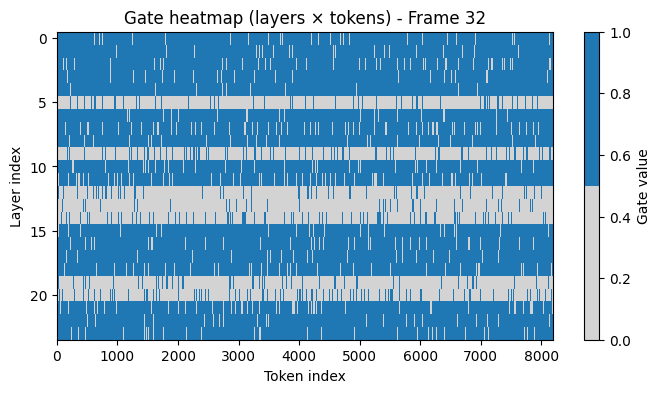

In [45]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import ListedColormap
from IPython.display import HTML

# Colormap for binary gates
cmap = ListedColormap(['#d3d3d3', '#1f77b4'])

# Prepare the list of matrices
# matrices = [x.detach().cpu().float().numpy().T for x in run_info['mask']]
matrices = [x.detach().cpu().float().numpy().T for x in population]

fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(matrices[0], aspect="auto", cmap=cmap, interpolation='nearest')
ax.set_xlabel("Token index")
ax.set_ylabel("Layer index")
ax.set_title("Gate heatmap (layers × tokens)")
cbar = plt.colorbar(im, ax=ax, label="Gate value")

def update(frame):
    im.set_data(matrices[frame])
    ax.set_title(f"Gate heatmap (layers × tokens) - Frame {frame+1}")
    return [im]

# Create animation
ani = FuncAnimation(fig, update, frames=len(matrices), blit=True)

# Display inline in Jupyter Notebook
HTML(ani.to_jshtml())


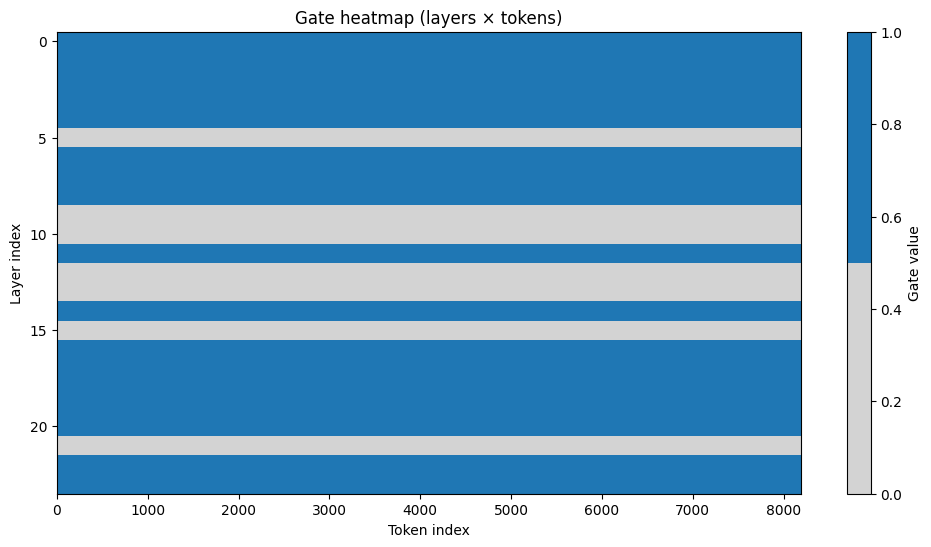

In [51]:
from matplotlib.colors import ListedColormap

sol = solution.detach().cpu().float().numpy().T

plt.figure(figsize=(12, 6))
plt.imshow(sol, aspect="auto", cmap=ListedColormap(['#d3d3d3', '#1f77b4']), interpolation='nearest')
plt.colorbar(label="Gate value")
plt.xlabel("Token index")
plt.ylabel("Layer index")
plt.title("Gate heatmap (layers × tokens)")
plt.show()

In [ ]:
plt.plot(run_info['ppl'])
plt.ylim(bottom=0)